## 1. Dataset Description

**Dataset:** Solar Energy – 137 PV Plants (Alabama)

**Dataset source:** The dataset is provided through the link https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/master/solar-energy/solar_AL.txt.gz. (`solar_AL.txt.gz`)

**Exact target:** Solar power generation of Plant #1 (column 1), predicted one time step ahead.

**Unit:** The physical measurement unit is not specified in the distributed `solar_AL.txt.gz` file or its repository description. Values are therefore reported in original dataset units.

**Native frequency:** One observation every 10 minutes.

**Resampling rule:** No resampling is performed. The original 10-minute sampling frequency is preserved.

**Coverage:** The dataset contains 52,560 observations corresponding to the calendar year 2006, from January 1 to December 31. The datetime index is reconstructed from the documented year and sampling frequency because the downloaded file does not contain explicit timestamps.

**Forecasting task:** Predict the next 10-minute solar generation value using the previous 36 observations (6 hours).

**Features:** Historical solar generation values of Plant #1 only (initial univariate forecasting setup).

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Check dataset location
data_path = Path("solar_AL.txt.gz")

print("File exists:", data_path.exists())

# Load dataset
df = pd.read_csv(
    data_path,
    compression="gzip",
    header=None
)

# Name the columns
df.columns = [f"Plant_{i+1}" for i in range(df.shape[1])]

print("Dataset shape:", df.shape)

display(df.head(10))

File exists: True
Dataset shape: (52560, 137)


,Plant_1,Plant_2,Plant_3,Plant_4,Plant_5,Plant_6,Plant_7,Plant_8,Plant_9,Plant_10,...,Plant_128,Plant_129,Plant_130,Plant_131,Plant_132,Plant_133,Plant_134,Plant_135,Plant_136,Plant_137
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
# Create datetime index

df.index = pd.date_range(
    start="2006-01-01 00:00:00",
    periods=len(df),
    freq="10min"
)

df.index.name = "Timestamp"

print("Start time:", df.index.min())
print("End time:", df.index.max())
print("Frequency:", df.index.freq)

display(df.head(10))

Start time: 2006-01-01 00:00:00
End time: 2006-12-31 23:50:00
Frequency: <10 * Minutes>


,Plant_1,Plant_2,Plant_3,Plant_4,Plant_5,Plant_6,Plant_7,Plant_8,Plant_9,Plant_10,...,Plant_128,Plant_129,Plant_130,Plant_131,Plant_132,Plant_133,Plant_134,Plant_135,Plant_136,Plant_137
Timestamp,,,,,,,,,,,,,,,,,,,,,
2006-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:40:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 00:50:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 01:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006-01-01 01:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data Audit
The data quality checks produced the following results:
- **Missing Values:** No missing values (NaN) were detected.
- **Duplicate Timestamps:** No duplicate timestamps were found in the reconstructed datetime index.
- **Sampling Frequency:** All consecutive timestamps have a consistent interval of 10 minutes.
- **Data Coverage:** The number of observations matches the expected 52,560 time steps for a complete year at 10-minute intervals.
- **Resampling:** No resampling was performed because the original 10-minute frequency was retained.

The dataset contains many zero-generation values, which are consistent with nighttime periods when solar generation is unavailable. These values were retained because they represent meaningful observations rather than missing data.

Since the original dataset does not contain explicit timestamps, the reconstructed index cannot independently verify whether any timestamps were missing or duplicated in the original data collection process. However, the dataset contains the expected number of observations for the documented period.

In [40]:
# 1. Expected number of observations
expected_rows = 365 * 24 * 6
print("Expected rows:", expected_rows)
print("Actual rows:", len(df))
print("Row count matches:", len(df) == expected_rows)

# 2. Missing values
print("\nMissing values:", df.isna().sum().sum())

# 3. Infinite values
print("Infinite values:", np.isinf(df.to_numpy()).sum())

# 4. Duplicate timestamps
print("Duplicate timestamps:", df.index.duplicated().sum())

# 5. Duplicate data rows (informational only)
print("Duplicate value rows:", df.duplicated().sum())

# 6. Timestamp interval check
intervals = df.index.to_series().diff().dropna()

print("\nInterval counts:")
print(intervals.value_counts())

# 7. Missing timestamps in constructed index
expected_index = pd.date_range(
    start="2006-01-01",
    periods=expected_rows,
    freq="10min"
)

print("\nMissing constructed timestamps:",
      len(expected_index.difference(df.index)))

# 8. Data value range
print("\nMinimum value:", df.min().min())
print("Maximum value:", df.max().max())

Expected rows: 52560
Actual rows: 52560
Row count matches: True

Missing values: 0
Infinite values: 0
Duplicate timestamps: 0
Duplicate value rows: 26938

Interval counts:
Timestamp
0 days 00:10:00    52559
Name: count, dtype: int64

Missing constructed timestamps: 0

Minimum value: 0.0
Maximum value: 88.9


## 3. Informative Exploratory Figures

Exploratory Data Analysis was performed on Plant #1 to understand the temporal patterns and variability in solar power generation before developing the forecasting models.

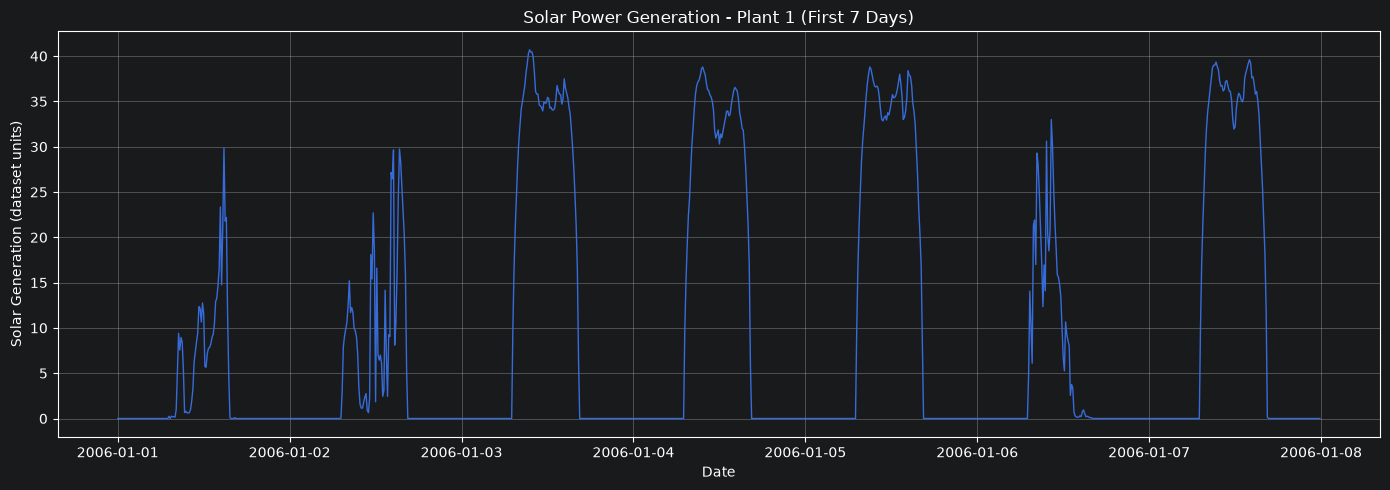

In [41]:
# Figure 1: Solar generation over 7 days (Plant 1)

plt.figure(figsize=(14, 5))

plt.plot(
    df.index[:1008],
    df["Plant_1"].iloc[:1008],
    linewidth=1
)

plt.title("Solar Power Generation - Plant 1 (First 7 Days)")
plt.xlabel("Date")
plt.ylabel("Solar Generation (dataset units)")
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 1: Solar Generation Over Seven Days**

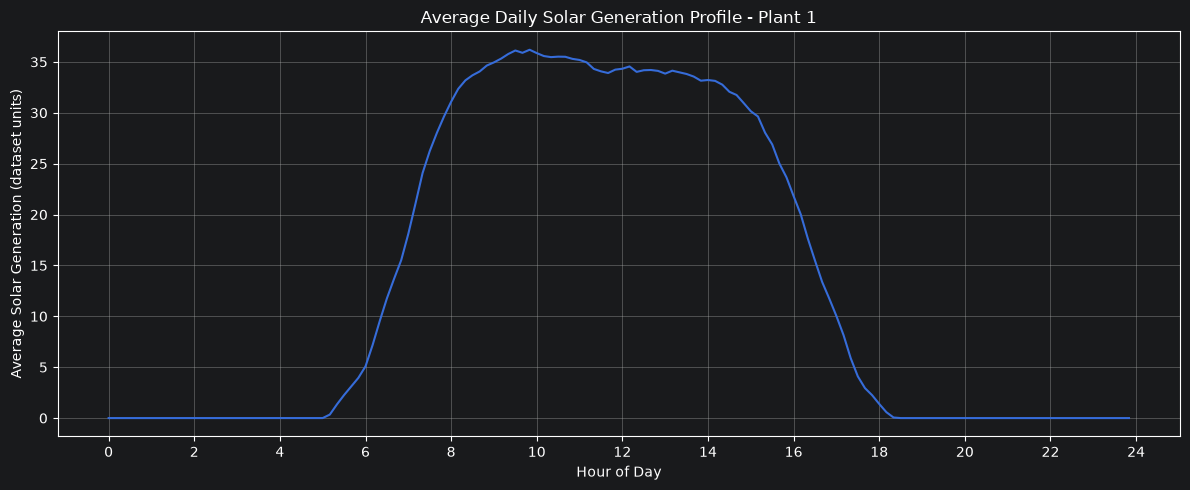

In [42]:
# Figure 2: Average solar generation by time of day (Plant 1)

plant = df["Plant_1"]

# Average generation at each 10-minute interval
daily_profile = plant.groupby(
    [plant.index.hour, plant.index.minute]
).mean()

# Convert time to decimal hours
hours = [
    hour + minute / 60
    for hour, minute in daily_profile.index
]

plt.figure(figsize=(12, 5))

plt.plot(hours, daily_profile.values)

plt.title("Average Daily Solar Generation Profile - Plant 1")
plt.xlabel("Hour of Day")
plt.ylabel("Average Solar Generation (dataset units)")
plt.xticks(range(0, 25, 2))
plt.grid(True)
plt.tight_layout()
plt.show()

**Figure 2: Average Daily Solar Generation Profile**